# WikiPulse — Exploratory Data Analysis

**Data:** 83,463 non-bot main-namespace edits from English Wikipedia, sampled by the MediaWiki Action API
as 170 random windows of 500 edits over the 30 days the API keeps (Phase 1, seed 42).
**Label:** `reverted` = the edit carries MediaWiki's `mw-reverted` tag, observed at least **72 h** after the edit;
younger edits are `pending` and excluded from label statistics.

Questions: What does the dataset look like? How imbalanced is the label? Which edit-time properties go together
with reverts? (Correlation only — no causal claims.)

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40, "display.width", 160)
LABELED = ROOT / "data" / "labeled" / "api_sample_seed42.w72h.csv"
print("data:", LABELED, "exists:", LABELED.exists())

data: /mnt/c/Users/HIKMAT/wikipulse/data/labeled/api_sample_seed42.w72h.csv exists: True


## 1. Dataset overview

In [2]:
raw = pd.read_csv(LABELED)
raw["timestamp_utc"] = pd.to_datetime(raw["timestamp_utc"], utc=True)
print(f"{len(raw):,} edits, {raw.page_id.nunique():,} distinct pages, {raw.editor.nunique():,} distinct editors")
print("time span:", raw.timestamp_utc.min(), "->", raw.timestamp_utc.max())
raw.head(3)

83,463 edits, 59,217 distinct pages, 21,782 distinct editors
time span: 2026-10-15 13:17:44+00:00 -> 2026-11-14 10:39:55+00:00


,rev_id,rc_id,page_id,parent_rev_id,page_title,namespace,editor,user_id,is_anonymous,timestamp_utc,byte_change,old_size,new_size,edit_summary,is_bot,is_minor,is_new_page,tags,source_method,collection_timestamp_utc,freshness_lag_ms,experiment_id,collection_status,label_observed_at,label_status,reverted,label_window_h
0,1380390357,2080042933,71586526,1.378403e+09,Alexandra Papadopoulou (diplomat),0,Umutdyb,40134685.0,False,2026-10-15 13:17:44+00:00,4,3823,3827,/* Early life and education */,False,False,False,"[""wikieditor""]",api,2026-11-14T12:31:14Z,2589210000,api_sample_seed42,ok,2026-11-14T12:31:14Z,labeled,0.0,72.0
1,1380390355,2080042931,77709991,1.380342e+09,Chuge,0,Zangxuangao,38473817.0,False,2026-10-15 13:17:45+00:00,26,14485,14511,NaN,False,True,False,"[""visualeditor""]",api,2026-11-14T12:31:14Z,2589209000,api_sample_seed42,ok,2026-11-14T12:31:14Z,labeled,0.0,72.0
2,1380390365,2080042961,140662,1.380390e+09,My Bloody Valentine (band),0,Basil the Bat Lord,19570710.0,False,2026-10-15 13:17:45+00:00,-9,80848,80839,NaN,False,True,False,"[""wikieditor""]",api,2026-11-14T12:31:14Z,2589209000,api_sample_seed42,ok,2026-11-14T12:31:14Z,labeled,0.0,72.0


In [3]:
nulls = raw.isna().sum()
nulls[nulls > 0].to_frame("null values")

,null values
parent_rev_id,1426
editor,4
user_id,4
edit_summary,13450
reverted,7500


Nulls are real: `edit_summary` is empty when the editor wrote none (or it was hidden), `parent_rev_id` is empty for page creations, `editor`/`user_id` when an administrator hid the username. Nothing was filled in.

## 2. Label status and class balance

In [4]:
print(raw.label_status.value_counts().to_string())
lab = raw[raw.label_status == "labeled"].copy()
lab["reverted"] = lab["reverted"].astype(int)
rate = lab.reverted.mean()
print(f"\nlabeled edits: {len(lab):,}  reverted: {lab.reverted.sum():,} ({rate:.2%})")
print(f"a model that always answers 'not reverted' would already be {1 - rate:.2%} accurate")

label_status
labeled    75963
pending     7500

labeled edits: 75,963  reverted: 5,625 (7.40%)
a model that always answers 'not reverted' would already be 92.60% accurate


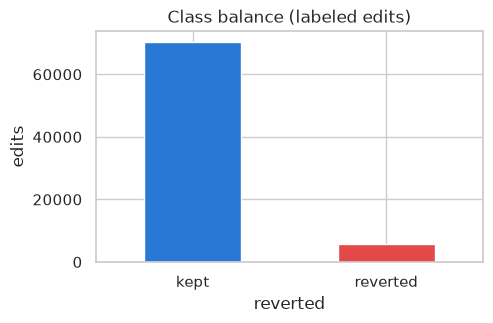

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
lab.reverted.map({0: "kept", 1: "reverted"}).value_counts().plot.bar(ax=ax, color=["#2a78d6", "#e34948"])
ax.set_title("Class balance (labeled edits)"); ax.set_ylabel("edits"); plt.xticks(rotation=0); plt.show()

## 3. When were the edits made? (sampling coverage)

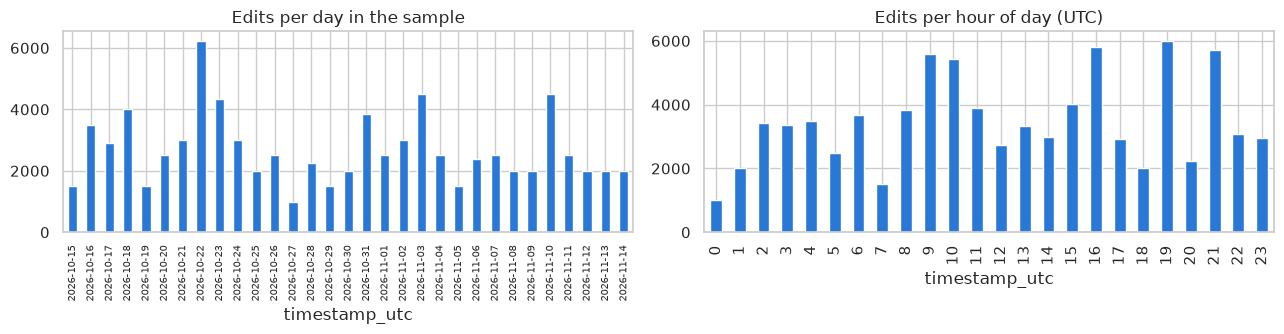

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
raw.timestamp_utc.dt.date.value_counts().sort_index().plot.bar(ax=axes[0], color="#2a78d6")
axes[0].set_title("Edits per day in the sample"); axes[0].tick_params(axis="x", labelsize=7)
raw.timestamp_utc.dt.hour.value_counts().sort_index().plot.bar(ax=axes[1], color="#2a78d6")
axes[1].set_title("Edits per hour of day (UTC)")
plt.tight_layout(); plt.show()

Counts per day/hour are uneven by design: each of the 170 windows covers ~10–15 minutes, placed at random. The sample is meant to cover all hours and weekdays, not to measure Wikipedia's activity curve.

## 4. Edit-time features

In [7]:
from src.ml.features import build_features, FEATURES
feat = build_features(lab)
feat[["log_abs_byte_change", "byte_sign", "log_old_size", "rel_change", "summary_len"]].describe().round(2)

,log_abs_byte_change,byte_sign,log_old_size,rel_change,summary_len
count,75963.00,75963.00,75963.00,75963.00,75963.00
mean,3.45,0.35,9.60,0.11,43.21
std,2.04,0.90,1.87,0.69,57.67
min,0.00,-1.00,0.00,-1.00,0.00
25%,1.95,-1.00,8.87,-0.00,9.00
50%,3.47,1.00,9.75,0.00,22.00
75%,4.78,1.00,10.70,0.01,55.00
max,12.39,1.00,13.48,5.00,500.00


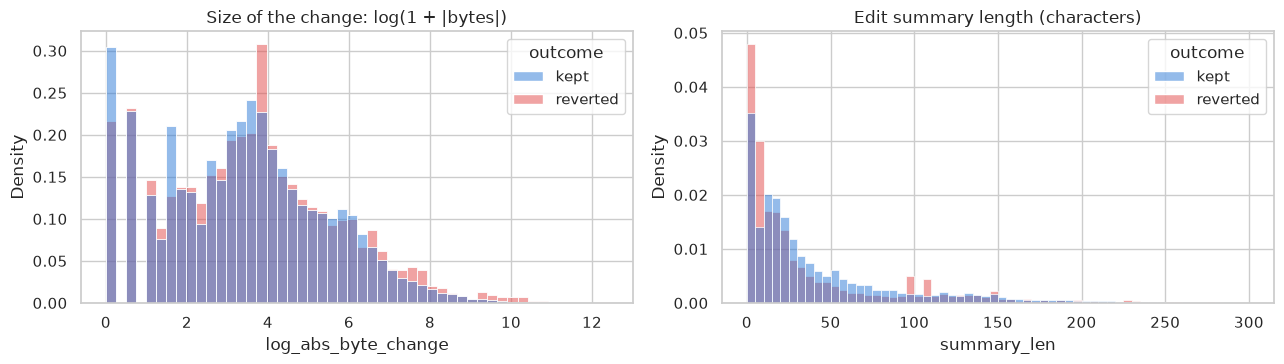

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(data=feat.assign(outcome=feat.reverted.map({0: "kept", 1: "reverted"})), x="log_abs_byte_change",
             hue="outcome", stat="density", common_norm=False, bins=50, ax=axes[0], palette=["#2a78d6", "#e34948"])
axes[0].set_title("Size of the change: log(1 + |bytes|)")
sns.histplot(data=feat.assign(outcome=feat.reverted.map({0: "kept", 1: "reverted"})), x="summary_len",
             hue="outcome", stat="density", common_norm=False, bins=60, binrange=(0, 300), ax=axes[1],
             palette=["#2a78d6", "#e34948"])
axes[1].set_title("Edit summary length (characters)")
plt.tight_layout(); plt.show()

## 5. Revert rate by edit-time property (95 % confidence intervals)

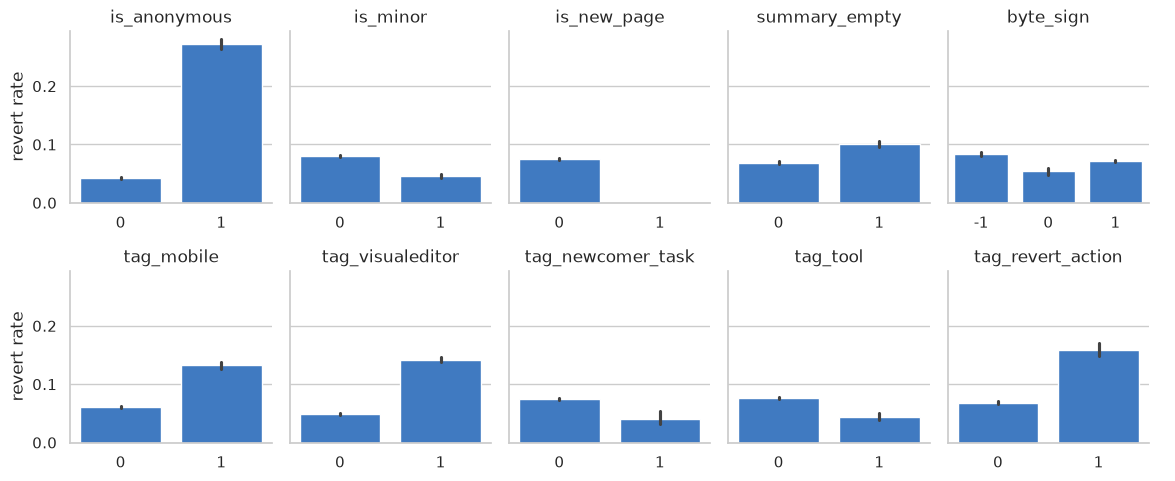

revert_rate_%  edits
property          value                      
byte_sign         -1              8.39  21907
                   0              5.39   5607
                   1              7.19  48449
is_anonymous       0              4.22  65430
                   1             27.21  10533
is_minor           0              8.03  61860
                   1              4.64  14103
is_new_page        0              7.53  74658
                   1              0.00   1305
summary_empty      0              6.88  63660
                   1             10.11  12303
tag_mobile         0              6.03  61396
                   1             13.21  14567
tag_newcomer_task  0              7.47  74505
                   1              4.12   1458
tag_revert_action  0              6.86  71415
                   1             15.94   4548
tag_tool           0              7.62  70942
                   1              4.38   5021
tag_visualeditor   0              4.90  55556
                   1             14.21  20407

In [9]:
props = ["is_anonymous", "is_minor", "is_new_page", "summary_empty", "byte_sign", "tag_mobile",
         "tag_visualeditor", "tag_newcomer_task", "tag_tool", "tag_revert_action"]
long = feat.melt(id_vars="reverted", value_vars=props, var_name="property", value_name="value")
g = sns.catplot(data=long, x="value", y="reverted", col="property", col_wrap=5, kind="bar", errorbar=("ci", 95),
                height=2.6, aspect=0.9, color="#2a78d6", sharex=False)
g.set_axis_labels("", "revert rate"); g.set_titles("{col_name}"); plt.show()
table = (long.groupby(["property", "value"]).reverted.agg(["mean", "size"])
         .rename(columns={"mean": "revert_rate", "size": "edits"}))
table.assign(revert_rate=lambda t: (t.revert_rate * 100).round(2)).rename(columns={"revert_rate": "revert_rate_%"})

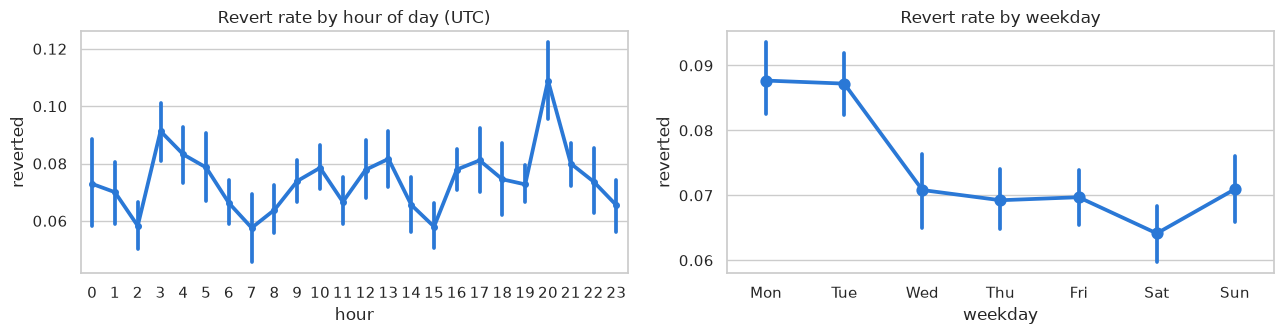

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
sns.pointplot(data=feat, x="hour", y="reverted", errorbar=("ci", 95), ax=axes[0], color="#2a78d6", markersize=3)
axes[0].set_title("Revert rate by hour of day (UTC)")
sns.pointplot(data=feat, x="weekday", y="reverted", errorbar=("ci", 95), ax=axes[1], color="#2a78d6")
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_title("Revert rate by weekday")
plt.tight_layout(); plt.show()

## 6. How the features relate to each other and to the label

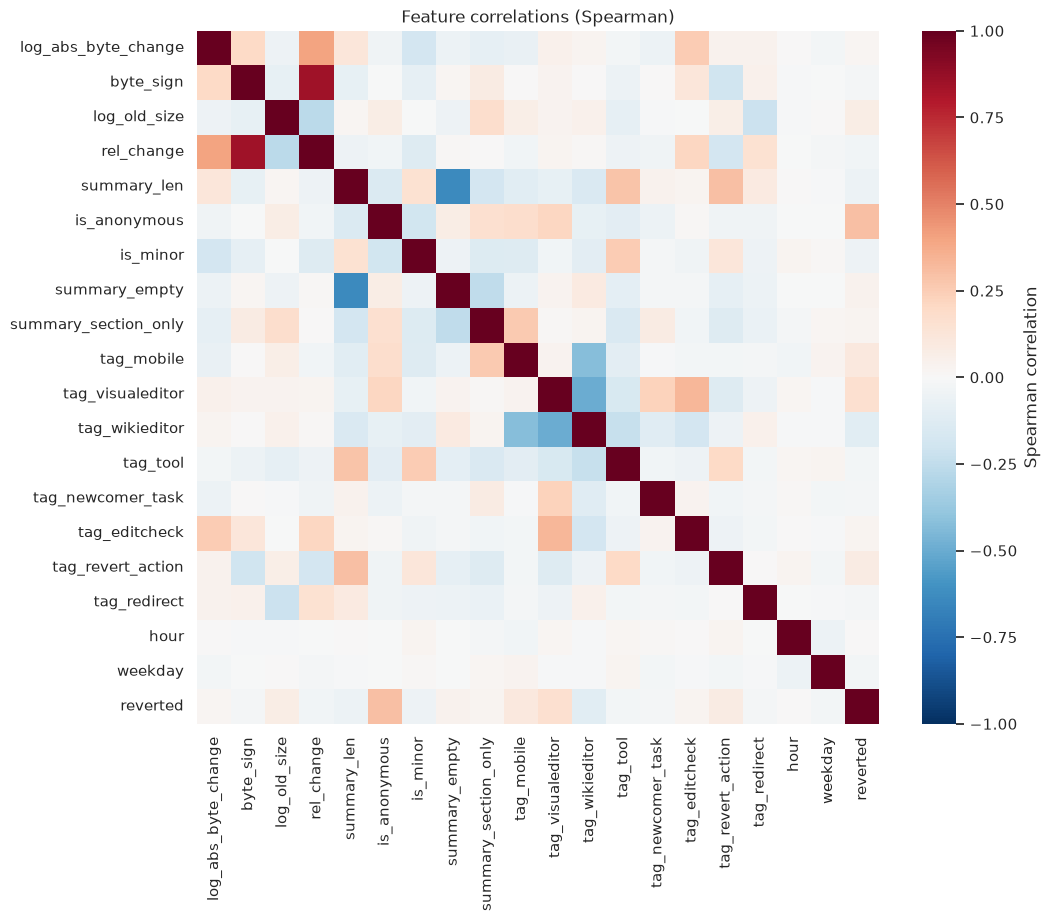

,corr. with reverted
is_anonymous,0.303
tag_visualeditor,0.158
tag_wikieditor,-0.113
tag_mobile,0.108
tag_revert_action,0.082
log_old_size,0.071
summary_len,-0.056
is_minor,-0.050
summary_empty,0.045
rel_change,-0.034


In [11]:
corr = feat[FEATURES + ["reverted"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman correlation"})
ax.set_title("Feature correlations (Spearman)"); plt.show()
corr["reverted"].drop("reverted").sort_values(key=abs, ascending=False).round(3).to_frame("corr. with reverted")

## 7. Label maturity: revert tag rate vs edit age (from Phase 1)

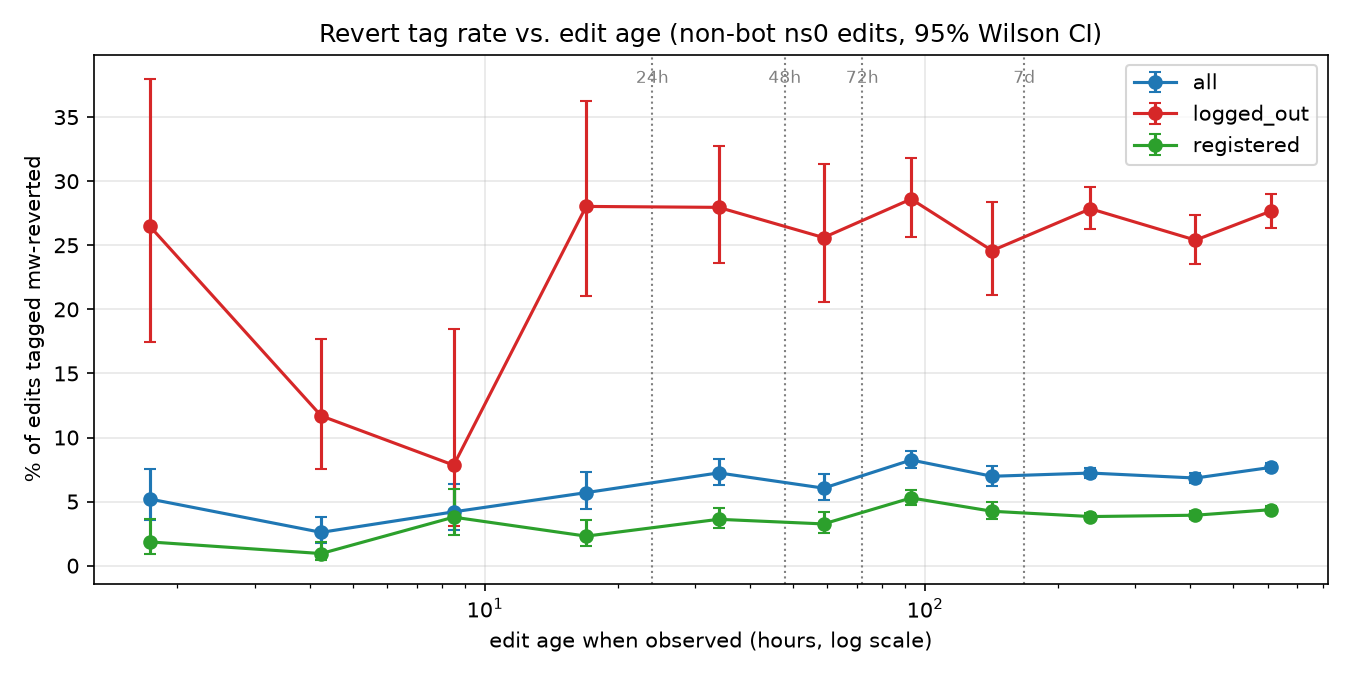

In [12]:
display(Image(filename=str(ROOT / "reports" / "figures" / "revert_rate_vs_age.png")))

## 8. Key observations
*(written after running the notebook — see the printed numbers above)*

1. **Strong class imbalance:** 75,963 labeled edits, 5,625 reverted (**7.40 %**). Always answering "kept" is already
   92.6 % accurate, so accuracy is useless as the main metric.
2. **Logged-out editors** (temporary accounts) are reverted **27.2 %** of the time vs **4.2 %** for registered editors —
   by far the strongest single signal (Spearman 0.30 with the label).
3. **Editing interface matters:** VisualEditor edits 14.2 % vs 4.9 % without; mobile edits 13.2 % vs 6.0 %. These overlap
   with logged-out editing (newcomers tend to use VisualEditor/mobile), so they are not independent evidence.
4. **Edits that are themselves undos/rollbacks** are reverted 15.9 % of the time (vs 6.9 %) — a sign of edit wars.
5. **Empty summary** 10.1 % vs 6.9 %; **minor** edits 4.6 % vs 8.0 %; removals (byte_sign −1) 8.4 % vs additions 7.2 %.
6. **Page creations: 0 of 1,305 reverted** — not because they are good, but because a bad new page is *deleted*, which
   MediaWiki does not tag as a revert. **Page creations are therefore excluded from the ML dataset** (labelling artefact).
7. Hour of day and weekday show only weak relations (|Spearman| ≤ 0.03); the sample covers all hours and weekdays.
8. `freshness_lag_ms` in this historical dataset is just "time since the edit" (days) — freshness is only meaningful
   in the live benchmark (Phase 3), not here.